# nb2 — Thin film on a substrate: simulated limits with the measured reference pulse, and the experimental polyimide-on-Si film

**Part A (simulation).** The measured nitrogen-purged reference pulse `data/Reference_15min_nitrogen.txt` (2425 points,
dt = 33 fs) is propagated in float64 through film (n = 3.6, κ = 0.0203, d = 5 … 100 µm) on substrate
(n = 2.213, κ = 0.0125, d = 496 µm); additive white Gaussian noise with σ = std of the first 10 ps of the measured
reference; three noise draws per thickness.  All six parameters are free; the fit is the scaled coarse-to-fine
L-BFGS of `RobustExtractor` (rMSE loss) from several random starts around the nominal values
(n ± 0.5, κ ± 0.01, d × [0.5, 1.5]); the best loss is kept.  No Bayesian pre-step.

**Part B (experiment).** Polyimide film on high-resistivity Si, `data/PI_silicon_ref_15min.txt` / `data/PI_silicon_15min.txt`
(1971 points, dt = 33 fs).  Stack air → PI → Si → air (transmission is invariant under reversal of the stack for air on
both sides, so the order does not matter); all six parameters free; same multi-start L-BFGS; nominal start
n_PI = 1.75, κ = 0.005, d = 25 µm, n_Si = 3.42, κ = 0.002, d = 400 µm.  Several starts expose the secondary minimum
(film collapsing to ≈ 16 µm).  Cramér–Rao bounds from J at the optimum and the measured pre-pulse σ.
Independent values: d_PI = 24.7 µm (profilometer), n∥(633 nm) = 1.726 (white-light reflectance).

Outputs: `figs/fig2_thin_film.*`, `results/nb2.json`, cache `results/nb2_cache.npz`.

In [1]:
import sys, os, json, time
sys.path.insert(0, '../code')
import numpy as np
import torch
import matplotlib.pyplot as plt

torch.set_num_threads(int(os.environ.get('NB_THREADS', 2)))
torch.set_default_dtype(torch.float64)

from RobustExtractor import RobustLayeredExtractor, Forward64, DT
import paperstyle as ps
ps.apply()

RUN_FULL = False                      # False -> load results/nb2_cache.npz for the sweep if present
CACHE = '../results/nb2_cache.npz'
os.makedirs('../figs', exist_ok=True); os.makedirs('../results', exist_ok=True)
C0 = 299792458.0

## Shared fit routine: multi-start coarse-to-fine L-BFGS around a nominal guess

In [2]:
SCHEDULE, MAX_ITER = (0.25e12, 0.5e12, 1.0e12, None), 300
JIT_N, JIT_K, JIT_D = 0.5, 0.01, 0.5           # start box: n ± 0.5, kappa ± 0.01 (clipped at 0), d x [1 - 0.5, 1 + 0.5]

def random_starts(nominal, n_starts, rng):
    """nominal: (n[m], kappa[m], d[m]).  Uniform draws in the start box; kappa >= 0."""
    n0, k0, d0 = (np.asarray(v, float) for v in nominal)
    out = []
    for _ in range(n_starts):
        n = n0 + rng.uniform(-JIT_N, JIT_N, len(n0))
        k = np.clip(k0 + rng.uniform(-JIT_K, JIT_K, len(k0)), 0.0, None)
        d = d0 * rng.uniform(1 - JIT_D, 1 + JIT_D, len(d0))
        out.append((n, k, d))
    return out

def multistart_fit(x_ref, y_meas, deltat, nominal, starts, verbose=False):
    """RobustLayeredExtractor centred on the nominal guess; coarse-to-fine L-BFGS from each start; best rMSE wins.
    Returns best (n, kappa, d, loss), the list of all start results and the total number of evaluations."""
    n0, k0, d0 = (np.asarray(v, float) for v in nominal)
    layers_init = [(n0[i] - 1j * k0[i], d0[i]) for i in range(len(n0))]      # RobustExtractor: n + i k, k < 0 = loss
    RE = RobustLayeredExtractor(x_ref, y_meas, deltat, layers_init)
    res = []
    for (n, k, d) in starts:
        x0 = RE._pack(torch.tensor(n), -torch.tensor(k), torch.tensor(d))
        e0 = len(RE.loss_history); t0 = time.time()
        x, l = RE.fit_from(x0, SCHEDULE, MAX_ITER, verbose=verbose)
        lay = RE._to_layers(x)
        res.append(dict(start=dict(n=n, kappa=k, d=d), n=np.array([q[0].real for q in lay]), kappa=-np.array([q[0].imag for q in lay]),
                        d=np.array([q[1] for q in lay]), loss=l, evals=len(RE.loss_history) - e0, wall=time.time() - t0))
    best = min(res, key=lambda r: r['loss'])
    return best, res, RE

## Part A — simulated sweep of the film thickness with the measured reference pulse and measured noise

In [3]:
data_ref = np.loadtxt('../data/Reference_15min_nitrogen.txt')
t_ref = data_ref[:, 0] - data_ref[0, 0]; x_ref = data_ref[:, 1].astype(np.float64)
L_A, dt_A = len(x_ref), (t_ref[1] - t_ref[0]) * 1e-12
SIGMA_A = float(np.std(x_ref[t_ref < 10.0]))
SNR_A_dB = float(10 * np.log10(np.mean(x_ref ** 2) / SIGMA_A ** 2))        # power SNR of the reference trace
print(f'measured reference: L = {L_A}, dt = {dt_A*1e15:.1f} fs, peak {np.abs(x_ref).max():.3f}; sigma (first 10 ps) = {SIGMA_A:.3e}'
      f' -> peak/sigma {np.abs(x_ref).max()/SIGMA_A:.0f}, power SNR 10 log10(<x^2>/sigma^2) = {SNR_A_dB:.0f} dB')

N_FILM, K_FILM = 3.6, 0.0203
N_SUB, K_SUB, D_SUB = 2.213, 0.0125, 496e-6
D_FILMS = np.array([5, 7, 10, 15, 20, 30, 50, 70, 100]) * 1e-6
N_DRAWS, N_STARTS_A, SEED_A = 3, 5, 1
fwd_A = Forward64(x_ref, dt_A)

def simulate_sample(d_film, seed):
    with torch.no_grad():
        y = fwd_A(torch.tensor([N_FILM, N_SUB]), -torch.tensor([K_FILM, K_SUB]), torch.tensor([d_film, D_SUB])).numpy()
    rng = np.random.default_rng(seed)
    return y + SIGMA_A * rng.standard_normal(len(y)), y

def run_sweep():
    rng = np.random.default_rng(SEED_A)
    rows = []
    for i, d_film in enumerate(D_FILMS):
        for draw in range(N_DRAWS):
            y_meas, y_clean = simulate_sample(d_film, 1000 * i + draw)
            nominal = ([N_FILM, N_SUB], [K_FILM, K_SUB], [d_film, D_SUB])
            t0 = time.time()
            best, res, _ = multistart_fit(x_ref, y_meas, dt_A, nominal, random_starts(nominal, N_STARTS_A, rng))
            rows.append(dict(d_film=d_film, draw=draw, n=best['n'], kappa=best['kappa'], d=best['d'], loss=best['loss'],
                             evals=int(sum(r['evals'] for r in res)), wall=time.time() - t0,
                             all_losses=[r['loss'] for r in res], all_d_film=[r['d'][0] for r in res], all_n_film=[r['n'][0] for r in res]))
            r = rows[-1]
            print(f"d = {d_film*1e6:5.1f} um draw {draw}: film n {r['n'][0]:.4f} k {r['kappa'][0]:.5f} d {r['d'][0]*1e6:7.3f} um | "
                  f"loss {r['loss']:.3e} = {r['loss']/SIGMA_A:.2f} sigma | starts {np.array2string(np.array(r['all_losses'])/SIGMA_A, precision=2)} | {r['wall']:.0f} s", flush=True)
    return rows

if RUN_FULL or not os.path.exists(CACHE):
    t0 = time.time(); rows = run_sweep(); T_SWEEP = time.time() - t0
    np.savez(CACHE, d_film=[r['d_film'] for r in rows], draw=[r['draw'] for r in rows], n=[r['n'] for r in rows], kappa=[r['kappa'] for r in rows],
             d=[r['d'] for r in rows], loss=[r['loss'] for r in rows], evals=[r['evals'] for r in rows], wall=[r['wall'] for r in rows],
             all_losses=[r['all_losses'] for r in rows], all_d_film=[r['all_d_film'] for r in rows], all_n_film=[r['all_n_film'] for r in rows], T_SWEEP=T_SWEEP)
else:
    z = np.load(CACHE)
    rows = [dict(d_film=float(z['d_film'][i]), draw=int(z['draw'][i]), n=z['n'][i], kappa=z['kappa'][i], d=z['d'][i], loss=float(z['loss'][i]),
                 evals=int(z['evals'][i]), wall=float(z['wall'][i]), all_losses=list(z['all_losses'][i]), all_d_film=list(z['all_d_film'][i]),
                 all_n_film=list(z['all_n_film'][i])) for i in range(len(z['loss']))]
    T_SWEEP = float(z['T_SWEEP']); print('loaded cache', CACHE)
print(f'sweep: {len(rows)} fits, {T_SWEEP/60:.1f} min')

measured reference: L = 2425, dt = 33.0 fs, peak 3.329; sigma (first 10 ps) = 1.580e-03 -> peak/sigma 2107, power SNR 10 log10(<x^2>/sigma^2) = 44 dB
loaded cache ../results/nb2_cache.npz
sweep: 27 fits, 2.5 min


In [4]:
# film errors (layer 1): |error| in %, median and range over the three draws
err = {q: np.zeros((len(D_FILMS), N_DRAWS)) for q in ('n', 'kappa', 'd')}
loss_tab = np.zeros((len(D_FILMS), N_DRAWS))
for r in rows:
    i = int(np.argmin(np.abs(D_FILMS - r['d_film']))); j = r['draw']
    err['n'][i, j] = 100 * abs(r['n'][0] - N_FILM) / N_FILM
    err['kappa'][i, j] = 100 * abs(r['kappa'][0] - K_FILM) / K_FILM
    err['d'][i, j] = 100 * abs(r['d'][0] - r['d_film']) / r['d_film']
    loss_tab[i, j] = r['loss']
round_trip_ps = 2 * N_FILM * D_FILMS / C0 * 1e12
print(f"{'d (um)':>7} {'2nd/c (ps)':>10} | {'|dn| % med':>10} {'range':>18} | {'|dk| % med':>10} {'range':>18} | {'|dd| % med':>10} {'range':>18} | {'loss/sigma':>10}")
for i, d in enumerate(D_FILMS):
    s = f"{d*1e6:7.0f} {round_trip_ps[i]:10.2f} |"
    for q in ('n', 'kappa', 'd'):
        s += f" {np.median(err[q][i]):10.3g} [{err[q][i].min():8.3g}, {err[q][i].max():8.3g}] |"
    s += f" {np.median(loss_tab[i])/SIGMA_A:10.3f}"
    print(s)

 d (um) 2nd/c (ps) | |dn| % med              range | |dk| % med              range | |dd| % med              range | loss/sigma
      5       0.12 |       1.89 [    1.11,     2.08] |       24.6 [    16.8,       44] |       4.84 [    3.07,     5.14] |      1.000
      7       0.17 |      0.618 [   0.139,     0.67] |       9.46 [    2.32,     23.7] |       1.75 [   0.362,     1.84] |      0.982
     10       0.24 |       0.29 [   0.286,    0.499] |       8.27 [    6.83,     19.5] |      0.987 [   0.555,     1.41] |      0.999
     15       0.36 |      0.113 [  0.0447,    0.132] |       5.73 [   0.829,     9.47] |      0.365 [   0.311,    0.372] |      1.000
     20       0.48 |     0.0252 [  0.0245,   0.0286] |       6.28 [   0.713,     6.33] |     0.0825 [ 0.00539,     0.17] |      0.998
     30       0.72 |     0.0409 [  0.0408,    0.102] |       4.89 [   0.834,     10.7] |     0.0459 [  0.0349,    0.207] |      0.994
     50       1.20 |      0.032 [  0.0252,   0.0463] |       2.49 [ 

## Part B — experimental polyimide on Si

In [5]:
def read_menlo(path):
    d = np.loadtxt(path, comments='#'); return d[:, 0] - d[0, 0], d[:, 1].astype(np.float64)
t_B, x_B = read_menlo('../data/PI_silicon_ref_15min.txt')
_, y_B = read_menlo('../data/PI_silicon_15min.txt')
L_B, dt_B = len(x_B), (t_B[1] - t_B[0]) * 1e-12
SIGMA_B = float(np.std(y_B[t_B < 10.0]))
ip = int(np.argmax(np.abs(y_B)))
print(f'PI/Si: L = {L_B}, dt = {dt_B*1e15:.2f} fs, window {t_B[-1]:.1f} ps; sample peak {y_B[ip]:.3f} at {t_B[ip]:.1f} ps; sigma (first 10 ps) = {SIGMA_B:.3e}')

NOMINAL_B = ([1.75, 3.42], [0.005, 0.002], [25e-6, 400e-6])
N_STARTS_B, SEED_B = 8, 2
rng_B = np.random.default_rng(SEED_B)
starts_B = [tuple(np.asarray(v, float) for v in NOMINAL_B)] + random_starts(NOMINAL_B, N_STARTS_B - 1, rng_B)
t0 = time.time()
best_B, res_B, RE_B = multistart_fit(x_B, y_B, dt_B, NOMINAL_B, starts_B)
T_B = time.time() - t0
print(f'\n{N_STARTS_B} starts in {T_B:.0f} s:')
print(f"{'start':>5} {'n_PI0':>6} {'d_PI0':>6} | {'n_PI':>7} {'k_PI':>8} {'d_PI/um':>8} {'n_Si':>7} {'k_Si':>8} {'d_Si/um':>8} | {'nd_PI':>7} {'nd_Si':>8} | {'rMSE/sigma':>10} {'evals':>5}")
for s, r in enumerate(res_B):
    print(f"{s:5d} {r['start']['n'][0]:6.3f} {r['start']['d'][0]*1e6:6.1f} | {r['n'][0]:7.4f} {r['kappa'][0]:8.5f} {r['d'][0]*1e6:8.3f} {r['n'][1]:7.4f} {r['kappa'][1]:8.5f} {r['d'][1]*1e6:8.2f} "
          f"| {r['n'][0]*r['d'][0]*1e6:7.2f} {r['n'][1]*r['d'][1]*1e6:8.2f} | {r['loss']/SIGMA_B:10.3f} {r['evals']:5d}")
ib = int(np.argmin([r['loss'] for r in res_B]))
print(f'best: start {ib}, rMSE {best_B["loss"]:.3e} = {best_B["loss"]/SIGMA_B:.2f} sigma')

# secondary minima.  (i) Random starts that did not reach the best loss (local minima of the coarse-to-fine fit);
# (ii) the plain full-band L-BFGS (no low-pass stages) from the nominal start and from a start with the film collapsed to
# 16 um, to show where a single-stage fit from a bad start ends up.
local = [r for r in res_B if r['loss'] > 1.005 * best_B['loss']]
print(f"\n{len(local)} of {N_STARTS_B} starts ended in a secondary minimum (rMSE > 0.5 % above the best):")
for r in local:
    print(f"   n_PI {r['n'][0]:.4f} kappa_PI {r['kappa'][0]:.4f} d_PI {r['d'][0]*1e6:.2f} um (n d {r['n'][0]*r['d'][0]*1e6:.2f} um), n_Si {r['n'][1]:.4f} d_Si {r['d'][1]*1e6:.2f} um, "
          f"rMSE {r['loss']/SIGMA_B:.3f} sigma ({100*(r['loss']/best_B['loss']-1):+.1f} %)")
plain = {}
for tag, d_start in (('nominal_25um', 25e-6), ('collapsed_16um', 16e-6)):
    x0 = RE_B._pack(torch.tensor([1.75, 3.42]), -torch.tensor([0.005, 0.002]), torch.tensor([d_start, 400e-6]))
    e0 = len(RE_B.loss_history); x, l = RE_B.fit_from(x0, (None,), MAX_ITER, verbose=False); lay = RE_B._to_layers(x)
    plain[tag] = dict(n_PI=lay[0][0].real, kappa_PI=-lay[0][0].imag, d_PI_um=lay[0][1] * 1e6, n_Si=lay[1][0].real, kappa_Si=-lay[1][0].imag, d_Si_um=lay[1][1] * 1e6,
                      nd_PI_um=lay[0][0].real * lay[0][1] * 1e6, rmse=l, rmse_over_sigma=l / SIGMA_B, loss_ratio_to_best=l / best_B['loss'], function_evaluations=len(RE_B.loss_history) - e0)
    print(f"plain full-band L-BFGS from d_PI = {tag}: n_PI {plain[tag]['n_PI']:.4f}, kappa_PI {plain[tag]['kappa_PI']:.4f}, d_PI {plain[tag]['d_PI_um']:.2f} um, "
          f"n_Si {plain[tag]['n_Si']:.4f}, d_Si {plain[tag]['d_Si_um']:.2f} um, rMSE {l/SIGMA_B:.3f} sigma ({100*(l/best_B['loss']-1):+.1f} %)")
# the same collapsed start with the coarse-to-fine schedule
_, c2f, _ = multistart_fit(x_B, y_B, dt_B, NOMINAL_B, [(np.array([1.75, 3.42]), np.array([0.005, 0.002]), np.array([16e-6, 400e-6]))])
c2f = c2f[0]
print(f"coarse-to-fine L-BFGS from d_PI = 16 um: n_PI {c2f['n'][0]:.4f}, d_PI {c2f['d'][0]*1e6:.2f} um, rMSE {c2f['loss']/SIGMA_B:.3f} sigma ({100*(c2f['loss']/best_B['loss']-1):+.2f} %)")

PI/Si: L = 1971, dt = 32.99 fs, window 65.0 ps; sample peak -2.487 at 15.4 ps; sigma (first 10 ps) = 1.349e-03



8 starts in 14 s:
start  n_PI0  d_PI0 |    n_PI     k_PI  d_PI/um    n_Si     k_Si  d_Si/um |   nd_PI    nd_Si | rMSE/sigma evals
    0  1.750   25.0 |  1.7184  0.00000   25.755  3.2591  0.00068   400.16 |   44.26  1304.18 |      2.690   380
    1  1.512   27.5 |  1.6113  0.01067   28.468  3.2547  0.00000   401.34 |   45.87  1306.22 |      3.340   253
    2  1.438   26.6 |  1.7128  0.00000   25.847  3.2590  0.00060   400.21 |   44.27  1304.29 |      2.687   358
    3  1.683   36.7 |  1.7114  0.00000   25.838  3.2591  0.00062   400.21 |   44.22  1304.33 |      2.688   356
    4  1.642   34.8 |  1.7125  0.00000   25.843  3.2592  0.00058   400.19 |   44.26  1304.30 |      2.687   436
    5  1.568   15.2 |  1.7111  0.00000   25.893  3.2589  0.00055   400.22 |   44.31  1304.29 |      2.690   381
    6  1.452   28.6 |  1.7031  0.00000   25.976  3.2591  0.00055   400.27 |   44.24  1304.52 |      2.691   401
    7  1.767   34.8 |  1.7238  0.01055   25.541  3.2587  0.00000   400.23 |   44.03  

plain full-band L-BFGS from d_PI = nominal_25um: n_PI 1.7116, kappa_PI 0.0000, d_PI 25.94 um, n_Si 3.2594, d_Si 400.15 um, rMSE 2.690 sigma (+0.1 %)


plain full-band L-BFGS from d_PI = collapsed_16um: n_PI 1.9288, kappa_PI 0.0051, d_PI 22.31 um, n_Si 3.2636, d_Si 398.41 um, rMSE 3.983 sigma (+48.2 %)


coarse-to-fine L-BFGS from d_PI = 16 um: n_PI 1.7156, d_PI 25.79 um, rMSE 2.688 sigma (+0.05 %)


### Cramér–Rao bounds and comparison with the independent measurements

In [6]:
fwd_B = Forward64(x_B, dt_B)
p_hat = np.concatenate([best_B['n'], best_B['kappa'], best_B['d']])         # (n_PI, n_Si, k_PI, k_Si, d_PI, d_Si)
PN_B = ['n_PI', 'n_Si', 'k_PI', 'k_Si', 'd_PI', 'd_Si']
def ysim_B(p):
    return fwd_B(p[0:2], -p[2:4], p[4:6])
J_B = torch.autograd.functional.jacobian(ysim_B, torch.tensor(p_hat, dtype=DT)).numpy()       # physical units
y_fit_B = ysim_B(torch.tensor(p_hat)).detach().numpy(); resid_B = y_B - y_fit_B
JtJ = J_B.T @ J_B; JtJ_inv = np.linalg.inv(JtJ)
cr_B = SIGMA_B * np.sqrt(np.diag(JtJ_inv))
corr_B = JtJ_inv / np.sqrt(np.outer(np.diag(JtJ_inv), np.diag(JtJ_inv)))
print('Cramer-Rao 1-sigma bounds (sigma = pre-pulse std, exact model assumed):')
for k, nm in enumerate(PN_B):
    sc = 1e6 if nm.startswith('d') else 1
    print(f"  {nm:5s} = {p_hat[k]*sc:10.5f} +- {cr_B[k]*sc:.2e}" + ('  um' if sc != 1 else ''))
print(f"  rho(n_PI, d_PI) = {corr_B[0, 4]:+.3f}, rho(n_Si, d_Si) = {corr_B[1, 5]:+.3f}")
# bound on the optical thickness n*d by linear error propagation
g = np.zeros(6); g[0] = p_hat[4]; g[4] = p_hat[0]; cr_nd_PI = SIGMA_B * np.sqrt(g @ JtJ_inv @ g)
g = np.zeros(6); g[1] = p_hat[5]; g[5] = p_hat[1]; cr_nd_Si = SIGMA_B * np.sqrt(g @ JtJ_inv @ g)
print(f"  n_PI d_PI = {p_hat[0]*p_hat[4]*1e6:.3f} +- {cr_nd_PI*1e6:.3f} um;  n_Si d_Si = {p_hat[1]*p_hat[5]*1e6:.2f} +- {cr_nd_Si*1e6:.3f} um")
D_PI_PROF, N_PI_VIS = 24.7e-6, 1.726
print(f"\nresidual: MAE {np.mean(np.abs(resid_B)):.3e} = {np.mean(np.abs(resid_B))/SIGMA_B:.1f} sigma, rMSE {best_B['loss']/SIGMA_B:.1f} sigma")
print(f"profilometer d_PI = {D_PI_PROF*1e6:.1f} um: fit differs by {(p_hat[4]-D_PI_PROF)*1e6:+.2f} um = {100*(p_hat[4]/D_PI_PROF-1):+.1f} % ({(p_hat[4]-D_PI_PROF)/cr_B[4]:.0f} CR sigma)")
print(f"visible n(633 nm) = {N_PI_VIS}: THz n_PI = {p_hat[0]:.3f} ({100*(p_hat[0]/N_PI_VIS-1):+.1f} %); n d / d_profilometer = {p_hat[0]*p_hat[4]/D_PI_PROF:.3f}")
print(f"film round trip 2 n d / c = {2*p_hat[0]*p_hat[4]/C0*1e12:.3f} ps; Si echo round trip {2*p_hat[1]*p_hat[5]/C0*1e12:.2f} ps")

Cramer-Rao 1-sigma bounds (sigma = pre-pulse std, exact model assumed):
  n_PI  =    1.71248 +- 2.43e-03
  n_Si  =    3.25921 +- 1.73e-04
  k_PI  =    0.00000 +- 1.77e-03
  k_Si  =    0.00058 +- 1.26e-04
  d_PI  =   25.84281 +- 6.18e-02  um
  d_Si  =  400.18993 +- 3.02e-02  um
  rho(n_PI, d_PI) = -0.933, rho(n_Si, d_Si) = -0.911
  n_PI d_PI = 44.255 +- 0.052 um;  n_Si d_Si = 1304.30 +- 0.045 um

residual: MAE 1.884e-03 = 1.4 sigma, rMSE 2.7 sigma
profilometer d_PI = 24.7 um: fit differs by +1.14 um = +4.6 % (18 CR sigma)
visible n(633 nm) = 1.726: THz n_PI = 1.712 (-0.8 %); n d / d_profilometer = 1.792
film round trip 2 n d / c = 0.295 ps; Si echo round trip 8.70 ps


## Results JSON

In [7]:
def rec(r):
    return dict(n_film=r['n'][0], kappa_film=r['kappa'][0], d_film_um=r['d'][0] * 1e6, n_sub=r['n'][1], kappa_sub=r['kappa'][1], d_sub_um=r['d'][1] * 1e6,
                loss=r['loss'], loss_over_sigma=r['loss'] / SIGMA_A, function_evaluations_all_starts=r['evals'], wall_time_s=r['wall'],
                start_losses_over_sigma=[l / SIGMA_A for l in r['all_losses']], start_d_film_um=[v * 1e6 for v in r['all_d_film']])
results = dict(
    notebook='nb2_thin_film_limits_and_PI.ipynb',
    partA=dict(
        reference='data/Reference_15min_nitrogen.txt (measured, used as is)', L=L_A, dt_fs=dt_A * 1e15, sigma=SIGMA_A, sigma_window='first 10 ps of the measured reference',
        reference_peak=float(np.abs(x_ref).max()), peak_over_sigma=float(np.abs(x_ref).max() / SIGMA_A), power_snr_dB=SNR_A_dB,
        film=dict(n=N_FILM, kappa=K_FILM, d_um=(D_FILMS * 1e6).tolist()), substrate=dict(n=N_SUB, kappa=K_SUB, d_um=D_SUB * 1e6),
        round_trip_ps=round_trip_ps.tolist(), n_draws=N_DRAWS, n_starts=N_STARTS_A, seed=SEED_A,
        protocol=dict(optimizer='coarse-to-fine L-BFGS (RobustExtractor), strong-Wolfe, history 50, max 300 iterations per stage', loss='rMSE + hinge against gain',
                      lowpass_schedule_THz=[0.25, 0.5, 1.0, None], scaling='n = n0 + 0.1 x, kappa = kappa0 + 0.005 x, d = d0 exp(0.1 x)',
                      start_box='n ± 0.5, kappa ± 0.01 (clipped >= 0), d x [0.5, 1.5] around the true values', precision='float64'),
        errors_percent={q: dict(median=np.median(err[q], axis=1).tolist(), min=err[q].min(axis=1).tolist(), max=err[q].max(axis=1).tolist(), per_draw=err[q].tolist()) for q in err},
        loss=dict(median=np.median(loss_tab, axis=1).tolist(), per_draw=loss_tab.tolist(), median_over_sigma=(np.median(loss_tab, axis=1) / SIGMA_A).tolist()),
        thresholds=dict(d_um_with_median_err_n_below_1pct=[float(d * 1e6) for d, e in zip(D_FILMS, np.median(err['n'], axis=1)) if e < 1],
                        d_um_with_median_err_d_below_1pct=[float(d * 1e6) for d, e in zip(D_FILMS, np.median(err['d'], axis=1)) if e < 1],
                        d_um_with_max_err_d_below_1pct=[float(d * 1e6) for d, e in zip(D_FILMS, err['d'].max(axis=1)) if e < 1]),
        fits=[rec(r) for r in rows], total_wall_time_s=T_SWEEP),
    partB=dict(
        data=dict(reference='data/PI_silicon_ref_15min.txt', sample='data/PI_silicon_15min.txt', stack='air -> PI -> Si -> air', L=L_B, dt_fs=dt_B * 1e15,
                  window_ps=float(t_B[-1]), sigma=SIGMA_B, sigma_window='first 10 ps of the sample trace', sample_peak=float(y_B[ip]), peak_time_ps=float(t_B[ip])),
        nominal_start=dict(n_PI=1.75, kappa_PI=0.005, d_PI_um=25.0, n_Si=3.42, kappa_Si=0.002, d_Si_um=400.0), n_starts=N_STARTS_B, seed=SEED_B, wall_time_s=T_B,
        starts=[dict(start=dict(n=r['start']['n'], kappa=r['start']['kappa'], d_um=r['start']['d'] * 1e6), n_PI=r['n'][0], kappa_PI=r['kappa'][0], d_PI_um=r['d'][0] * 1e6,
                     n_Si=r['n'][1], kappa_Si=r['kappa'][1], d_Si_um=r['d'][1] * 1e6, nd_PI_um=r['n'][0] * r['d'][0] * 1e6, nd_Si_um=r['n'][1] * r['d'][1] * 1e6,
                     loss=r['loss'], loss_over_sigma=r['loss'] / SIGMA_B, function_evaluations=r['evals']) for r in res_B],
        best=dict(start=ib, n_PI=p_hat[0], kappa_PI=p_hat[2], d_PI_um=p_hat[4] * 1e6, n_Si=p_hat[1], kappa_Si=p_hat[3], d_Si_um=p_hat[5] * 1e6,
                  nd_PI_um=p_hat[0] * p_hat[4] * 1e6, nd_Si_um=p_hat[1] * p_hat[5] * 1e6, rmse=best_B['loss'], rmse_over_sigma=best_B['loss'] / SIGMA_B,
                  mae=float(np.mean(np.abs(resid_B))), mae_over_sigma=float(np.mean(np.abs(resid_B)) / SIGMA_B),
                  film_round_trip_ps=2 * p_hat[0] * p_hat[4] / C0 * 1e12, si_round_trip_ps=2 * p_hat[1] * p_hat[5] / C0 * 1e12),
        secondary_minima=dict(
            criterion='rMSE more than 0.5 % above the best of the eight starts',
            from_random_starts=[dict(n_PI=r['n'][0], kappa_PI=r['kappa'][0], d_PI_um=r['d'][0] * 1e6, n_Si=r['n'][1], kappa_Si=r['kappa'][1], d_Si_um=r['d'][1] * 1e6,
                                     nd_PI_um=r['n'][0] * r['d'][0] * 1e6, rmse=r['loss'], rmse_over_sigma=r['loss'] / SIGMA_B, loss_ratio_to_best=r['loss'] / best_B['loss']) for r in local],
            n_random_starts_in_secondary_minima=len(local), n_random_starts_with_d_PI_below_20um=int(sum(r['d'][0] < 20e-6 for r in res_B)),
            plain_full_band_lbfgs=plain,
            coarse_to_fine_from_16um=dict(n_PI=c2f['n'][0], kappa_PI=c2f['kappa'][0], d_PI_um=c2f['d'][0] * 1e6, n_Si=c2f['n'][1], d_Si_um=c2f['d'][1] * 1e6,
                                          rmse=c2f['loss'], rmse_over_sigma=c2f['loss'] / SIGMA_B, loss_ratio_to_best=c2f['loss'] / best_B['loss'])),
        cramer_rao=dict(sigma=SIGMA_B, bounds={nm: cr_B[k] for k, nm in enumerate(PN_B)}, bounds_d_um={'d_PI': cr_B[4] * 1e6, 'd_Si': cr_B[5] * 1e6},
                        bound_nd_PI_um=cr_nd_PI * 1e6, bound_nd_Si_um=cr_nd_Si * 1e6, rho_n_d_PI=corr_B[0, 4], rho_n_d_Si=corr_B[1, 5],
                        correlation=corr_B, parameter_order=PN_B),
        independent=dict(d_PI_profilometer_um=D_PI_PROF * 1e6, n_PI_visible_633nm=N_PI_VIS,
                         d_PI_fit_minus_profilometer_um=(p_hat[4] - D_PI_PROF) * 1e6, d_PI_fit_minus_profilometer_percent=100 * (p_hat[4] / D_PI_PROF - 1),
                         d_PI_difference_in_CR_sigma=(p_hat[4] - D_PI_PROF) / cr_B[4],
                         n_PI_THz_minus_visible=p_hat[0] - N_PI_VIS, n_PI_THz_over_visible_percent=100 * (p_hat[0] / N_PI_VIS - 1),
                         nd_over_profilometer_d=p_hat[0] * p_hat[4] / D_PI_PROF)),
)
json.dump(ps.to_jsonable(results), open('../results/nb2.json', 'w'), indent=1)
print('wrote ../results/nb2.json')

wrote ../results/nb2.json


# Loop-1 checks (domain review of 2026-11-24)

Appended after the loop-0 analysis; every result goes to `results/nb2.json` under `loop1_checks`.

* **C14** pre-pulse noise table of all six measured traces (std over 0–5 / 0–10 / 5–10 ps, 2-ps segments, white
  component from first differences, autocorrelation length).
* **C1** polyimide/Si refit (same coarse-to-fine multi-start, same 8 starts) under model variants:
  (a) $n_{\rm Si}$ fixed at 3.4175, $d_{\rm Si}$ free; (b) as (a) plus a free reference delay $\tau$ and amplitude $a$,
  $y = a\,\mathcal F^{-1}[T X e^{-i\omega\tau}]$; (c) everything free plus $\tau$, $a$; (d) as (b) with $d_{\rm PI}$ fixed at the
  profilometer value 24.7 µm (cost of the profilometer thickness).
* **C6** (PI/Si part) Cramér–Rao bounds with and without the $\tau$, $a$ columns in $J$.
* **C11** (a) CR bounds of the film parameters per thickness for the sweep geometry and the reference pulse FWHM;
  (b) 10 further noise draws at 5–20 µm with a tight full-band re-polish of the best start;
  (c) a PI-like sweep (film 1.72 / 0.01 on Si 3.4175 / 1e-4 / 400 µm, PI reference, σ of the PI sample trace).

In [8]:
from loop1_tools import noise_stats, TauAmpExtractor, jacobian_tau_amp, cr_from_J, pulse_fwhm
LOOP1 = dict(date='2026-11-24', source='reviews/loop1_domain.md section 5')
N_SI_LIT = 3.4175
T_LOOP1 = {}

# ---- C14: noise table of the six measured traces
TRACES = {'quartzSi_reference': 'Reference_15min_nitrogen.txt', 'quartzSi_sample': 'Quartz_Si_15min_nitrogen.txt',
          'PI_reference': 'PI_silicon_ref_15min.txt', 'PI_sample': 'PI_silicon_15min.txt',
          'run3_reference': 'ref_3.txt', 'run3_sample': 'quartz_air_silicon_15_min_3.txt'}
c14 = {}
print(f"{'trace':20s} {'std 0-5':>9s} {'std 0-10':>9s} {'std 5-10':>9s} | {'white min':>9s} {'white med':>9s} {'std10/white':>11s} | {'max|mean|':>9s} | {'ACF 1/e':>7s} {'tau_int':>7s} (ps)")
for key, fn in TRACES.items():
    dd = np.loadtxt('../data/' + fn, comments='#')
    c14[key] = dict(file='data/' + fn, **noise_stats(dd[:, 0], dd[:, 1]))
    q = c14[key]
    print(f"{key:20s} {q['std_0_5ps']:9.2e} {q['std_0_10ps']:9.2e} {q['std_5_10ps']:9.2e} | {q['white_min']:9.2e} {q['white_median']:9.2e} {q['ratio_std10_over_white_min']:11.1f} | "
          f"{q['max_abs_segment_mean']:9.2e} | {q['acf_1_over_e_ps']:7.2f} {q['integrated_corr_time_ps']:7.2f}")
LOOP1['C14_noise_table'] = dict(description='pre-pulse noise of the six measured traces; white = std(first difference)/sqrt(2) per 2-ps segment '
                                            '(min = quietest segment); ACF of the demeaned 0-10 ps window', traces=c14)

trace                  std 0-5  std 0-10  std 5-10 | white min white med std10/white | max|mean| | ACF 1/e tau_int (ps)
quartzSi_reference    1.11e-03  1.58e-03  1.93e-03 |  4.53e-05  7.56e-05        34.8 |  5.81e-04 |    0.26    0.39
quartzSi_sample       2.23e-04  2.90e-04  2.18e-04 |  4.51e-05  4.77e-05         6.4 |  5.51e-04 |    0.76    2.22
PI_reference          2.12e-03  6.50e-03  8.94e-03 |  1.14e-04  2.89e-04        57.1 |  1.87e-03 |    0.26    0.39
PI_sample             1.03e-03  1.35e-03  1.60e-03 |  1.87e-05  8.10e-05        72.3 |  5.74e-04 |    0.26    0.40
run3_reference        1.82e-03  2.40e-02  3.38e-02 |  2.83e-05  4.12e-04       848.4 |  1.49e-02 |    0.30    0.48
run3_sample           4.72e-04  9.04e-04  1.19e-03 |  2.69e-05  3.07e-05        33.6 |  3.48e-04 |    0.23    0.37


In [9]:
# ---- C1: PI/Si model variants (same 8 starts, same coarse-to-fine schedule, rMSE + hinge)
def multistart_variant(nominal, starts, n_si_fixed=None, d_pi_fixed=None, free_ta=False):
    n0, k0, d0 = (np.array(v, float) for v in nominal)
    mask = [[True, True, True], [True, True, True]]
    if n_si_fixed is not None:
        n0[1] = n_si_fixed; mask[1][0] = False
    if d_pi_fixed is not None:
        d0[0] = d_pi_fixed; mask[0][2] = False
    RE = TauAmpExtractor(x_B, y_B, dt_B, [(n0[i] - 1j * k0[i], d0[i]) for i in range(2)],
                         optimize_mask=[tuple(m) for m in mask], free_tau_amp=free_ta)
    out = []
    for (n, k, d) in starts:
        n = np.array(n, float); d = np.array(d, float)
        if n_si_fixed is not None: n[1] = n_si_fixed
        if d_pi_fixed is not None: d[0] = d_pi_fixed
        e0 = len(RE.loss_history)
        x, l = RE.fit_from(RE._pack(torch.tensor(n), -torch.tensor(k), torch.tensor(d)), SCHEDULE, MAX_ITER, verbose=False)
        lay = RE._to_layers(x); tau, a = RE.tau_amp(x)
        nP, kP, dP = lay[0][0].real, -lay[0][0].imag, lay[0][1]; nS, kS, dS = lay[1][0].real, -lay[1][0].imag, lay[1][1]
        out.append(dict(n_PI=nP, kappa_PI=kP, d_PI_um=dP * 1e6, nd_PI_um=nP * dP * 1e6, n_Si=nS, kappa_Si=kS, d_Si_um=dS * 1e6, nd_Si_um=nS * dS * 1e6,
                        d_PI_plus_d_Si_um=(dP + dS) * 1e6, sum_n_minus_1_d_um=((nP - 1) * dP + (nS - 1) * dS) * 1e6,
                        tau_fs=tau * 1e15, amplitude=a, rmse=l, rmse_over_sigma=l / SIGMA_B, function_evaluations=len(RE.loss_history) - e0))
    return out

VARIANTS = {'loop0_all_free': dict(),
            'a_nSi_fixed': dict(n_si_fixed=N_SI_LIT),
            'b_nSi_fixed_tau_amp_free': dict(n_si_fixed=N_SI_LIT, free_ta=True),
            'c_all_free_tau_amp_free': dict(free_ta=True),
            'd_nSi_and_dPI_fixed_tau_amp_free': dict(n_si_fixed=N_SI_LIT, d_pi_fixed=D_PI_PROF, free_ta=True)}
c1 = {}
t0 = time.time()
for name, kw in VARIANTS.items():
    if name == 'loop0_all_free':      # the loop-0 result, re-expressed in the same record format
        res = [dict(n_PI=r['n'][0], kappa_PI=r['kappa'][0], d_PI_um=r['d'][0] * 1e6, nd_PI_um=r['n'][0] * r['d'][0] * 1e6, n_Si=r['n'][1], kappa_Si=r['kappa'][1],
                    d_Si_um=r['d'][1] * 1e6, nd_Si_um=r['n'][1] * r['d'][1] * 1e6, d_PI_plus_d_Si_um=(r['d'][0] + r['d'][1]) * 1e6,
                    sum_n_minus_1_d_um=((r['n'][0] - 1) * r['d'][0] + (r['n'][1] - 1) * r['d'][1]) * 1e6, tau_fs=0.0, amplitude=1.0,
                    rmse=r['loss'], rmse_over_sigma=r['loss'] / SIGMA_B, function_evaluations=r['evals']) for r in res_B]
    else:
        res = multistart_variant(NOMINAL_B, starts_B, **kw)
    ib_v = int(np.argmin([r['rmse'] for r in res])); bv = res[ib_v]
    agree = [r for r in res if r['rmse'] <= 1.005 * bv['rmse']]
    c1[name] = dict(settings={k: (v * 1e6 if k == 'd_pi_fixed' else v) for k, v in kw.items()}, starts=res, best_start=ib_v, best=bv,
                    n_starts_within_0p5pct=len(agree),
                    spread_within_0p5pct=dict(d_PI_um=float(np.ptp([r['d_PI_um'] for r in agree])), nd_PI_um=float(np.ptp([r['nd_PI_um'] for r in agree])),
                                              n_PI=float(np.ptp([r['n_PI'] for r in agree])), tau_fs=float(np.ptp([r['tau_fs'] for r in agree]))),
                    rmse_ratio_to_loop0_best=bv['rmse'] / best_B['loss'],
                    d_PI_minus_profilometer_um=bv['d_PI_um'] - D_PI_PROF * 1e6)
    print(f"{name:34s} best start {ib_v}: n_PI {bv['n_PI']:.4f} k_PI {bv['kappa_PI']:.2e} d_PI {bv['d_PI_um']:7.3f} um (nd {bv['nd_PI_um']:6.2f}) | "
          f"n_Si {bv['n_Si']:.4f} k_Si {bv['kappa_Si']:.2e} d_Si {bv['d_Si_um']:7.2f} | tau {bv['tau_fs']:+7.1f} fs a {bv['amplitude']:.4f} | "
          f"rMSE {bv['rmse_over_sigma']:.3f} sigma ({100*(bv['rmse']/best_B['loss']-1):+.1f} % vs loop 0); {len(agree)}/8 starts within 0.5 %")
T_LOOP1['C1_s'] = time.time() - t0
print(f'C1: {T_LOOP1["C1_s"]:.0f} s')

# ---- C6 (PI/Si): Cramér–Rao bounds of the loop-0 optimum with and without tau, a in J
J_ta = jacobian_tau_amp(fwd_B, p_hat[0:2], p_hat[2:4], p_hat[4:6])          # columns n_PI n_Si k_PI k_Si d_PI d_Si tau a
names_ta = PN_B + ['tau', 'a']
def lin_bound(cov, g): return float(np.sqrt(g @ cov @ g))
c6 = {}
for tag, cols in (('without_tau_a', list(range(6))), ('with_tau_a', list(range(8)))):
    cov, bnd = cr_from_J(J_ta[:, cols], SIGMA_B)
    g_sum = np.zeros(len(cols)); g_sum[4] = g_sum[5] = 1.0
    g_ndPI = np.zeros(len(cols)); g_ndPI[0] = p_hat[4]; g_ndPI[4] = p_hat[0]
    c6[tag] = dict(bounds={names_ta[c]: bnd[i] for i, c in enumerate(cols)}, d_PI_nm=bnd[4] * 1e9, d_Si_nm=bnd[5] * 1e9, n_PI=bnd[0], n_Si=bnd[1],
                   d_PI_plus_d_Si_nm=lin_bound(cov, g_sum) * 1e9, nd_PI_nm=lin_bound(cov, g_ndPI) * 1e9,
                   tau_fs=(bnd[6] * 1e15 if len(cols) > 6 else None), a=(bnd[7] if len(cols) > 6 else None))
    print(f"C6 PI/Si CR {tag:14s}: d_PI {c6[tag]['d_PI_nm']:.0f} nm, d_Si {c6[tag]['d_Si_nm']:.0f} nm, d_PI+d_Si {c6[tag]['d_PI_plus_d_Si_nm']:.0f} nm, "
          f"n_PI d_PI {c6[tag]['nd_PI_nm']:.0f} nm, n_PI {c6[tag]['n_PI']:.1e}, n_Si {c6[tag]['n_Si']:.1e}" + (f", tau {c6[tag]['tau_fs']:.2f} fs" if c6[tag]['tau_fs'] else ''))
LOOP1['C1_PI_model_variants'] = dict(description='PI/Si refit, same 8 starts and coarse-to-fine L-BFGS as loop 0; rmse_over_sigma uses sigma of the PI sample trace (R12)',
                                     n_Si_literature=N_SI_LIT, d_PI_profilometer_um=D_PI_PROF * 1e6, variants=c1, wall_time_s=T_LOOP1['C1_s'])
LOOP1['C6_PI_cramer_rao_tau_amp'] = dict(point='loop-0 best fit', sigma=SIGMA_B, **c6)
LOOP1['independent_nd_visible_index_times_profilometer_um'] = N_PI_VIS * D_PI_PROF * 1e6

loop0_all_free                     best start 4: n_PI 1.7125 k_PI 2.23e-13 d_PI  25.843 um (nd  44.26) | n_Si 3.2592 k_Si 5.79e-04 d_Si  400.19 | tau    +0.0 fs a 1.0000 | rMSE 2.687 sigma (+0.0 % vs loop 0); 6/8 starts within 0.5 %


a_nSi_fixed                        best start 3: n_PI 2.9978 k_PI 2.18e-03 d_PI 117.045 um (nd 350.88) | n_Si 3.4175 k_Si 5.36e-05 d_Si  283.60 | tau    +0.0 fs a 1.0000 | rMSE 18.056 sigma (+572.0 % vs loop 0); 5/8 starts within 0.5 %


b_nSi_fixed_tau_amp_free           best start 2: n_PI 1.7792 k_PI 2.62e-02 d_PI  25.249 um (nd  44.92) | n_Si 3.4175 k_Si 2.24e-13 d_Si  381.60 | tau   -65.4 fs a 1.0219 | rMSE 1.704 sigma (-36.6 % vs loop 0); 6/8 starts within 0.5 %


c_all_free_tau_amp_free            best start 0: n_PI 1.7836 k_PI 2.86e-02 d_PI  25.238 um (nd  45.01) | n_Si 3.4297 k_Si 3.31e-14 d_Si  380.24 | tau   -70.1 fs a 1.0244 | rMSE 1.696 sigma (-36.9 % vs loop 0); 2/8 starts within 0.5 %


d_nSi_and_dPI_fixed_tau_amp_free   best start 7: n_PI 1.8013 k_PI 3.05e-02 d_PI  24.700 um (nd  44.49) | n_Si 3.4175 k_Si 2.04e-14 d_Si  381.51 | tau   -65.0 fs a 1.0241 | rMSE 1.749 sigma (-34.9 % vs loop 0); 5/8 starts within 0.5 %
C1: 55 s


C6 PI/Si CR without_tau_a : d_PI 62 nm, d_Si 30 nm, d_PI+d_Si 73 nm, n_PI d_PI 52 nm, n_PI 2.4e-03, n_Si 1.7e-04
C6 PI/Si CR with_tau_a    : d_PI 64 nm, d_Si 251 nm, d_PI+d_Si 273 nm, n_PI d_PI 52 nm, n_PI 2.7e-03, n_Si 2.0e-03, tau 0.87 fs


In [10]:
# ---- C11 (a): Cramér–Rao bounds of the film parameters at the true values, per thickness; reference pulse FWHM
def cr_sweep(fwd, nf, kf, df, ns, ks, ds, sigma):
    J = jacobian_tau_amp(fwd, np.array([nf, ns]), np.array([kf, ks]), np.array([df, ds]))[:, :6]     # n_f n_s k_f k_s d_f d_s
    _, b = cr_from_J(J, sigma)
    return dict(n=b[0], kappa=b[2], d=b[4], n_percent=100 * b[0] / nf, kappa_percent=100 * b[2] / kf, d_percent=100 * b[4] / df)
cr_A = [cr_sweep(fwd_A, N_FILM, K_FILM, d, N_SUB, K_SUB, D_SUB, SIGMA_A) for d in D_FILMS]
fwhm_A = pulse_fwhm(t_ref, x_ref)
print(f"reference pulse: field-peak FWHM {fwhm_A['field_peak_fwhm_ps']:.3f} ps, intensity-envelope FWHM {fwhm_A['intensity_envelope_fwhm_ps']:.3f} ps")
print(f"{'d (um)':>7} {'2nd/c':>6} | CR 1-sigma (%):  {'n':>8} {'kappa':>8} {'d':>8} | median |err| loop 0 (3 draws) / (0.674 CR): {'n':>6} {'kappa':>6} {'d':>6}")
for i, d in enumerate(D_FILMS):
    c = cr_A[i]
    print(f"{d*1e6:7.0f} {round_trip_ps[i]:6.2f} | {'':16s} {c['n_percent']:8.3g} {c['kappa_percent']:8.3g} {c['d_percent']:8.3g} | {'':41s} "
          f"{np.median(err['n'][i])/(0.674*c['n_percent']):6.2f} {np.median(err['kappa'][i])/(0.674*c['kappa_percent']):6.2f} {np.median(err['d'][i])/(0.674*c['d_percent']):6.2f}")

# ---- C11 (b): 10 further noise draws at 5–20 um (5 starts each, same start box) + tight full-band re-polish of the best start
D_THIN = np.array([5, 7, 10, 15, 20]) * 1e-6
N_DRAWS_B, N_STARTS_C11, POLISH_ITER = 10, 5, 1500
rng_b = np.random.default_rng(11)
rows_b = []
t0 = time.time()
for i, d_film in enumerate(D_THIN):
    for draw in range(N_DRAWS_B):
        y_meas, _ = simulate_sample(d_film, 50000 + 1000 * i + draw)
        nominal = ([N_FILM, N_SUB], [K_FILM, K_SUB], [d_film, D_SUB])
        best, res, RE = multistart_fit(x_ref, y_meas, dt_A, nominal, random_starts(nominal, N_STARTS_C11, rng_b))
        RE._set_lowpass(None)
        xb = RE._pack(torch.tensor(best['n']), -torch.tensor(best['kappa']), torch.tensor(best['d']))
        xp, lp, _ = RE._lbfgs(xb, POLISH_ITER); lay = RE._to_layers(xp)
        n_p, k_p, d_p = lay[0][0].real, -lay[0][0].imag, lay[0][1]
        same = [r for r in res if r['loss'] <= best['loss'] * (1 + 1e-4)]
        rows_b.append(dict(d_film_um=d_film * 1e6, draw=draw, n=best['n'][0], kappa=best['kappa'][0], d_um=best['d'][0] * 1e6, loss_over_sigma=best['loss'] / SIGMA_A,
                           polished=dict(n=n_p, kappa=k_p, d_um=d_p * 1e6, loss_over_sigma=lp / SIGMA_A),
                           polish_shift=dict(n=n_p - best['n'][0], kappa=k_p - best['kappa'][0], d_um=(d_p - best['d'][0]) * 1e6),
                           n_starts_within_1em4=len(same), spread_d_um_within_1em4=float(np.ptp([r['d'][0] for r in same]) * 1e6),
                           spread_n_within_1em4=float(np.ptp([r['n'][0] for r in same]))))
    print(f"d = {d_film*1e6:4.0f} um: {N_DRAWS_B} draws done ({time.time()-t0:.0f} s)", flush=True)
T_LOOP1['C11b_s'] = time.time() - t0

def errs(rows_, key_n='n', key_k='kappa', key_d='d_um', pol=False):
    g = (lambda r: r['polished']) if pol else (lambda r: r)
    return (np.array([100 * (g(r)[key_n] - N_FILM) / N_FILM for r in rows_]), np.array([100 * (g(r)[key_k] - K_FILM) / K_FILM for r in rows_]),
            np.array([100 * (g(r)[key_d] - r['d_film_um']) / r['d_film_um'] for r in rows_]))
c11b = []
print(f"\n{'d':>4} | median |err| % (10 draws, after polish) n / kappa / d | ratio to 0.674 CR | mean signed err % (± s.e.) d | polish |shift d| max (um) | start spread d at equal loss (um, median)")
for i, d_film in enumerate(D_THIN):
    rr = [r for r in rows_b if abs(r['d_film_um'] - d_film * 1e6) < 1e-6]
    en, ek, ed = errs(rr, pol=True); en0, ek0, ed0 = errs(rr)
    j = int(np.argmin(np.abs(D_FILMS - d_film))); c = cr_A[j]
    # the 3 loop-0 draws (signed) + these 10 -> 13 draws
    old = [r for r in rows if abs(r['d_film'] - d_film) < 1e-12]
    ed13 = np.r_[ed, [100 * (r['d'][0] - r['d_film']) / r['d_film'] for r in old]]
    en13 = np.r_[en, [100 * (r['n'][0] - N_FILM) / N_FILM for r in old]]
    ek13 = np.r_[ek, [100 * (r['kappa'][0] - K_FILM) / K_FILM for r in old]]
    rec_ = dict(d_film_um=d_film * 1e6, n_draws=len(rr),
                median_abs_err_percent=dict(n=np.median(np.abs(en)), kappa=np.median(np.abs(ek)), d=np.median(np.abs(ed))),
                median_abs_err_percent_before_polish=dict(n=np.median(np.abs(en0)), kappa=np.median(np.abs(ek0)), d=np.median(np.abs(ed0))),
                range_abs_err_percent=dict(n=[np.abs(en).min(), np.abs(en).max()], kappa=[np.abs(ek).min(), np.abs(ek).max()], d=[np.abs(ed).min(), np.abs(ed).max()]),
                mean_signed_err_percent=dict(n=en.mean(), kappa=ek.mean(), d=ed.mean()),
                std_err_percent=dict(n=en.std(ddof=1), kappa=ek.std(ddof=1), d=ed.std(ddof=1)),
                cr_percent=dict(n=c['n_percent'], kappa=c['kappa_percent'], d=c['d_percent']),
                ratio_median_abs_err_to_0p674_cr=dict(n=np.median(np.abs(en)) / (0.674 * c['n_percent']), kappa=np.median(np.abs(ek)) / (0.674 * c['kappa_percent']),
                                                      d=np.median(np.abs(ed)) / (0.674 * c['d_percent'])),
                ratio_std_err_to_cr=dict(n=en.std(ddof=1) / c['n_percent'], kappa=ek.std(ddof=1) / c['kappa_percent'], d=ed.std(ddof=1) / c['d_percent']),
                thirteen_draws=dict(median_abs_err_percent=dict(n=np.median(np.abs(en13)), kappa=np.median(np.abs(ek13)), d=np.median(np.abs(ed13))),
                                    range_abs_err_percent=dict(n=[np.abs(en13).min(), np.abs(en13).max()], kappa=[np.abs(ek13).min(), np.abs(ek13).max()],
                                                               d=[np.abs(ed13).min(), np.abs(ed13).max()])),
                polish_max_abs_shift=dict(d_um=float(np.max([abs(r['polish_shift']['d_um']) for r in rr])), n=float(np.max([abs(r['polish_shift']['n']) for r in rr]))),
                polish_loss_change_over_sigma_max=float(np.max([r['loss_over_sigma'] - r['polished']['loss_over_sigma'] for r in rr])),
                start_spread_d_um_at_equal_loss_median=float(np.median([r['spread_d_um_within_1em4'] for r in rr])),
                loss_over_sigma_median=float(np.median([r['polished']['loss_over_sigma'] for r in rr])))
    c11b.append(rec_)
    q = rec_
    print(f"{d_film*1e6:4.0f} | {q['median_abs_err_percent']['n']:7.3g} {q['median_abs_err_percent']['kappa']:7.3g} {q['median_abs_err_percent']['d']:7.3g} | "
          f"{q['ratio_median_abs_err_to_0p674_cr']['n']:5.2f} {q['ratio_median_abs_err_to_0p674_cr']['kappa']:5.2f} {q['ratio_median_abs_err_to_0p674_cr']['d']:5.2f} | "
          f"{q['mean_signed_err_percent']['d']:+7.3f} ± {q['std_err_percent']['d']/np.sqrt(len(rr)):.3f} | {q['polish_max_abs_shift']['d_um']:.2e} | {q['start_spread_d_um_at_equal_loss_median']:.3f}")
print(f'C11b: {T_LOOP1["C11b_s"]:.0f} s')

reference pulse: field-peak FWHM 0.355 ps, intensity-envelope FWHM 0.511 ps
 d (um)  2nd/c | CR 1-sigma (%):         n    kappa        d | median |err| loop 0 (3 draws) / (0.674 CR):      n  kappa      d
      5   0.12 |                      2.21     46.3     5.89 |                                             1.26   0.79   1.22
      7   0.17 |                     0.901     27.5     2.44 |                                             1.02   0.51   1.06
     10   0.24 |                     0.337     16.4    0.943 |                                             1.28   0.75   1.55
     15   0.36 |                     0.105       10    0.299 |                                             1.60   0.85   1.81
     20   0.48 |                     0.055     7.65    0.132 |                                             0.68   1.22   0.93
     30   0.72 |                    0.0439      5.8    0.068 |                                             1.38   1.25   1.00
     50   1.20 |                    0.04

d =    5 um: 10 draws done (51 s)


d =    7 um: 10 draws done (106 s)


d =   10 um: 10 draws done (172 s)


d =   15 um: 10 draws done (254 s)


d =   20 um: 10 draws done (321 s)



   d | median |err| % (10 draws, after polish) n / kappa / d | ratio to 0.674 CR | mean signed err % (± s.e.) d | polish |shift d| max (um) | start spread d at equal loss (um, median)
   5 |   0.635    20.3    1.35 |  0.43  0.65  0.34 |  +1.280 ± 1.498 | 1.69e-07 | 0.076
   7 |   0.644    10.7    1.64 |  1.06  0.58  1.00 |  -1.079 ± 0.754 | 8.46e-09 | 0.019
  10 |   0.296    16.8   0.856 |  1.30  1.53  1.35 |  -0.212 ± 0.292 | 1.96e-04 | 0.000
  15 |  0.0931    10.7   0.282 |  1.32  1.59  1.40 |  -0.132 ± 0.107 | 2.77e-04 | 0.000
  20 |    0.06    6.49   0.121 |  1.62  1.26  1.36 |  +0.053 ± 0.048 | 1.81e-08 | 0.000
C11b: 321 s


In [11]:
# ---- C11 (c): PI-like sweep — film 1.72 / 0.01 on Si 3.4175 / 1e-4 / 400 um, the measured PI reference, sigma of the PI sample
N_PIL, K_PIL, N_SIL, K_SIL, D_SIL = 1.72, 0.01, N_SI_LIT, 1e-4, 400e-6
D_PIL = np.array([10, 15, 20, 25, 30, 40]) * 1e-6
N_DRAWS_C, N_STARTS_C = 5, 5
rng_c = np.random.default_rng(12)
rows_c = []
t0 = time.time()
for i, d_film in enumerate(D_PIL):
    with torch.no_grad():
        y_clean = fwd_B(torch.tensor([N_PIL, N_SIL]), -torch.tensor([K_PIL, K_SIL]), torch.tensor([d_film, D_SIL])).numpy()
    for draw in range(N_DRAWS_C):
        y_meas = y_clean + SIGMA_B * np.random.default_rng(90000 + 1000 * i + draw).standard_normal(len(y_clean))
        nominal = ([N_PIL, N_SIL], [K_PIL, K_SIL], [d_film, D_SIL])
        best, res, _ = multistart_fit(x_B, y_meas, dt_B, nominal, random_starts(nominal, N_STARTS_C, rng_c))
        rows_c.append(dict(d_film_um=d_film * 1e6, draw=draw, n=best['n'][0], kappa=best['kappa'][0], d_um=best['d'][0] * 1e6, nd_um=best['n'][0] * best['d'][0] * 1e6,
                           n_Si=best['n'][1], d_Si_um=best['d'][1] * 1e6, loss_over_sigma=best['loss'] / SIGMA_B))
    print(f"PI-like d = {d_film*1e6:4.0f} um done ({time.time()-t0:.0f} s)", flush=True)
T_LOOP1['C11c_s'] = time.time() - t0
cr_C = [cr_sweep(fwd_B, N_PIL, K_PIL, d, N_SIL, K_SIL, D_SIL, SIGMA_B) for d in D_PIL]
c11c = []
print(f"\n{'d':>4} {'2nd/c':>6} | median |err| % n / kappa / d / nd | range d | CR % n / kappa / d")
for i, d_film in enumerate(D_PIL):
    rr = [r for r in rows_c if abs(r['d_film_um'] - d_film * 1e6) < 1e-6]
    en = np.array([100 * (r['n'] - N_PIL) / N_PIL for r in rr]); ek = np.array([100 * (r['kappa'] - K_PIL) / K_PIL for r in rr])
    ed = np.array([100 * (r['d_um'] - r['d_film_um']) / r['d_film_um'] for r in rr]); end_ = np.array([100 * (r['nd_um'] / (N_PIL * r['d_film_um']) - 1) for r in rr])
    c = cr_C[i]
    q = dict(d_film_um=d_film * 1e6, round_trip_ps=2 * N_PIL * d_film / C0 * 1e12, n_draws=len(rr),
             median_abs_err_percent=dict(n=np.median(np.abs(en)), kappa=np.median(np.abs(ek)), d=np.median(np.abs(ed)), nd=np.median(np.abs(end_))),
             range_abs_err_percent=dict(n=[np.abs(en).min(), np.abs(en).max()], kappa=[np.abs(ek).min(), np.abs(ek).max()], d=[np.abs(ed).min(), np.abs(ed).max()],
                                        nd=[np.abs(end_).min(), np.abs(end_).max()]),
             mean_signed_err_percent=dict(n=en.mean(), kappa=ek.mean(), d=ed.mean(), nd=end_.mean()),
             cr_percent=dict(n=c['n_percent'], kappa=c['kappa_percent'], d=c['d_percent']),
             loss_over_sigma_median=float(np.median([r['loss_over_sigma'] for r in rr])), fits=rr)
    c11c.append(q)
    print(f"{d_film*1e6:4.0f} {q['round_trip_ps']:6.3f} | {q['median_abs_err_percent']['n']:6.3g} {q['median_abs_err_percent']['kappa']:6.3g} {q['median_abs_err_percent']['d']:6.3g} "
          f"{q['median_abs_err_percent']['nd']:6.3g} | [{np.abs(ed).min():.3g}, {np.abs(ed).max():.3g}] | {c['n_percent']:.3g} {c['kappa_percent']:.3g} {c['d_percent']:.3g}")
print(f'C11c: {T_LOOP1["C11c_s"]:.0f} s')
fresnel = lambda a, b: abs((a - b) / (a + b))
LOOP1['C11_sweep'] = dict(
    a_cramer_rao=dict(description='CR 1-sigma bounds of the film parameters at the true values (sweep geometry, sigma of the reference pre-pulse, white noise, exact model); '
                                  'for an efficient unbiased estimator the median |error| is 0.674 x CR',
                      d_um=(D_FILMS * 1e6).tolist(), bounds=cr_A, reference_fwhm=fwhm_A,
                      ratio_median_abs_err_loop0_to_0p674_cr=[dict(n=float(np.median(err['n'][i]) / (0.674 * cr_A[i]['n_percent'])),
                                                                   kappa=float(np.median(err['kappa'][i]) / (0.674 * cr_A[i]['kappa_percent'])),
                                                                   d=float(np.median(err['d'][i]) / (0.674 * cr_A[i]['d_percent']))) for i in range(len(D_FILMS))]),
    b_ten_draws=dict(description='10 additional noise draws (seeds 50000+1000 i+draw) at 5-20 um, 5 starts each, best start re-polished with full-band L-BFGS '
                                 f'({POLISH_ITER} iterations, tolerances 1e-12); errors after polish', n_starts=N_STARTS_C11, per_thickness=c11b, fits=rows_b,
                     wall_time_s=T_LOOP1['C11b_s']),
    c_PI_like=dict(description='film n 1.72, kappa 0.01 on Si 3.4175 / 1e-4 / 400 um; measured PI reference pulse; white noise sigma = PI sample pre-pulse std; '
                               '5 draws x 5 starts, same coarse-to-fine L-BFGS and start box', film=dict(n=N_PIL, kappa=K_PIL), substrate=dict(n=N_SIL, kappa=K_SIL, d_um=D_SIL * 1e6),
                   sigma=SIGMA_B, per_thickness=c11c, wall_time_s=T_LOOP1['C11c_s'],
                   echo_fresnel_product=dict(sweep=fresnel(N_FILM, 1) * fresnel(N_FILM, N_SUB), PI_like=fresnel(N_PIL, 1) * fresnel(N_PIL, N_SIL)),
                   reference_fwhm=pulse_fwhm(t_B, x_B)))

PI-like d =   10 um done (31 s)


PI-like d =   15 um done (64 s)


PI-like d =   20 um done (113 s)


PI-like d =   25 um done (152 s)


PI-like d =   30 um done (184 s)


PI-like d =   40 um done (228 s)



   d  2nd/c | median |err| % n / kappa / d / nd | range d | CR % n / kappa / d
  10  0.115 |    1.2   28.1   1.85  0.738 | [0.0534, 3.93] | 2.26 105 3.2
  15  0.172 |   0.35   30.2  0.326  0.107 | [0.108, 10.5] | 0.707 52.2 1.06
  20  0.229 |  0.202     14  0.275  0.104 | [0.0465, 0.877] | 0.302 29.4 0.474
  25  0.287 | 0.0434   16.7  0.156  0.128 | [0.0138, 0.582] | 0.156 18.6 0.261
  30  0.344 | 0.0197   10.5 0.0728  0.053 | [0.0585, 0.122] | 0.0955 13 0.171
  40  0.459 |  0.044    7.9 0.0567 0.0225 | [0.0425, 0.187] | 0.0552 7.79 0.104
C11c: 228 s


## Fig. 2(b) variant (R27): PI/Si fit with a free reference time offset τ and amplitude a
The C1 variant with the lower rMSE of (b) n_Si fixed + τ, a and (c) everything free + τ, a is shown in Fig. 2(b).

In [12]:
from loop1_tools import tau_amp_filter
cand = {k: c1[k] for k in ('b_nSi_fixed_tau_amp_free', 'c_all_free_tau_amp_free')}
FIG2B = min(cand, key=lambda k: cand[k]['best']['rmse'])
bv = c1[FIG2B]['best']
pv = np.array([bv['n_PI'], bv['n_Si'], bv['kappa_PI'], bv['kappa_Si'], bv['d_PI_um'] * 1e-6, bv['d_Si_um'] * 1e-6])
with torch.no_grad():
    y_fit_v = (bv['amplitude'] * Forward64(x_B, dt_B)(torch.tensor(pv[0:2]), -torch.tensor(pv[2:4]), torch.tensor(pv[4:6]),
                                                       tau_amp_filter(fwd_B.freqs, torch.tensor(bv['tau_fs'] * 1e-15), torch.tensor(1.0)))).numpy()
resid_v = y_B - y_fit_v
assert abs(np.sqrt(np.mean(resid_v ** 2)) / bv['rmse'] - 1) < 1e-6
# CR bounds at this point with tau and a in the Jacobian (parameters fixed in the variant are excluded)
def _y_v(q):          # q = n_PI n_Si k_PI k_Si d_PI d_Si tau a
    return q[7] * fwd_B(q[0:2], -q[2:4], q[4:6], tau_amp_filter(fwd_B.freqs, q[6], torch.tensor(1.0)))
J_v = torch.autograd.functional.jacobian(_y_v, torch.tensor(np.r_[pv, bv['tau_fs'] * 1e-15, bv['amplitude']])).numpy()   # at the fitted tau, a
at_bound = dict(kappa_PI=bool(bv['kappa_PI'] < 1e-9), kappa_Si=bool(bv['kappa_Si'] < 1e-9))
cols = [i for i, nm in enumerate(names_ta) if not (nm == 'n_Si' and FIG2B.startswith('b_')) and not (nm == 'k_PI' and at_bound['kappa_PI']) and not (nm == 'k_Si' and at_bound['kappa_Si'])]
cov_v, bnd_v = cr_from_J(J_v[:, cols], SIGMA_B)
bnd_named = {names_ta[c]: bnd_v[i] for i, c in enumerate(cols)}
gi = {names_ta[c]: i for i, c in enumerate(cols)}
g_nd = np.zeros(len(cols)); g_nd[gi['n_PI']] = pv[4]; g_nd[gi['d_PI']] = pv[0]
nd_all = [r['nd_PI_um'] for r in c1[FIG2B]['starts']]
agree_v = [r for r in c1[FIG2B]['starts'] if r['rmse'] <= 1.005 * bv['rmse']]
fig2b = dict(variant=FIG2B, reason='lower rMSE of C1 variants (b) and (c)', rmse_b=cand['b_nSi_fixed_tau_amp_free']['best']['rmse'], rmse_c=cand['c_all_free_tau_amp_free']['best']['rmse'],
             n_PI=bv['n_PI'], kappa_PI=bv['kappa_PI'], kappa_PI_at_bound=at_bound['kappa_PI'], d_PI_um=bv['d_PI_um'], nd_PI_um=bv['nd_PI_um'],
             n_Si=bv['n_Si'], kappa_Si=bv['kappa_Si'], kappa_Si_at_bound=at_bound['kappa_Si'], d_Si_um=bv['d_Si_um'], tau_fs=bv['tau_fs'], amplitude=bv['amplitude'],
             rmse=bv['rmse'], rmse_over_sigma=bv['rmse_over_sigma'], sigma=SIGMA_B,
             cramer_rao=dict(note='J includes tau and a; parameters at a bound or fixed are excluded (no CR entry)', parameters=[names_ta[c] for c in cols],
                             n_PI=bnd_named['n_PI'], d_PI_nm=bnd_named['d_PI'] * 1e9, nd_PI_nm=float(np.sqrt(g_nd @ cov_v @ g_nd)) * 1e9,
                             n_Si=bnd_named.get('n_Si'), d_Si_nm=bnd_named['d_Si'] * 1e9, kappa_PI=bnd_named.get('k_PI'), kappa_Si=bnd_named.get('k_Si'),
                             tau_fs=bnd_named['tau'] * 1e15, a=bnd_named['a']),
             nd_PI_spread_all_8_starts=dict(min_um=min(nd_all), max_um=max(nd_all), spread_percent=100 * np.ptp(nd_all) / bv['nd_PI_um']),
             nd_PI_spread_starts_within_0p5pct=dict(n=len(agree_v), min_um=min(r['nd_PI_um'] for r in agree_v), max_um=max(r['nd_PI_um'] for r in agree_v),
                                                     spread_percent=100 * np.ptp([r['nd_PI_um'] for r in agree_v]) / bv['nd_PI_um']),
             d_PI_minus_profilometer_um=bv['d_PI_um'] - D_PI_PROF * 1e6)
LOOP1['fig2b_variant'] = fig2b
print(f"Fig. 2(b) variant: {FIG2B} (rMSE (b) {fig2b['rmse_b']:.5e}, (c) {fig2b['rmse_c']:.5e})")
print(json.dumps(ps.to_jsonable({k: v for k, v in fig2b.items()}), indent=1)[:2500])

Fig. 2(b) variant: c_all_free_tau_amp_free (rMSE (b) 2.29882e-03, (c) 2.28733e-03)
{
 "variant": "c_all_free_tau_amp_free",
 "reason": "lower rMSE of C1 variants (b) and (c)",
 "rmse_b": 0.002298821753670818,
 "rmse_c": 0.0022873285291895337,
 "n_PI": 1.7835803135359394,
 "kappa_PI": 0.02858112139032052,
 "kappa_PI_at_bound": false,
 "d_PI_um": 25.238029446634773,
 "nd_PI_um": 45.014052473458115,
 "n_Si": 3.4296605138371743,
 "kappa_Si": 3.31119680285763e-14,
 "kappa_Si_at_bound": true,
 "d_Si_um": 380.23755859339457,
 "tau_fs": -70.1414746359997,
 "amplitude": 1.0244113583276728,
 "rmse": 0.0022873285291895337,
 "rmse_over_sigma": 1.6956249704265933,
 "sigma": 0.001348958979186345,
 "cramer_rao": {
  "note": "J includes tau and a; parameters at a bound or fixed are excluded (no CR entry)",
  "parameters": [
   "n_PI",
   "n_Si",
   "k_PI",
   "d_PI",
   "d_Si",
   "tau",
   "a"
  ],
  "n_PI": 0.0018892447888502553,
  "d_PI_nm": 38.142353137582184,
  "nd_PI_nm": 37.38460059015413,
  "n

## Figure 2 (loop 1): (a) sweep errors with the CR 1σ curves and the PI-like prediction at 25 µm; (b) PI/Si fit, residual ×10 and ±σ

Exported at the final width (13.3 cm); every font ≥ 7 pt at that size (checked by `ps.savefig`).

saved ../figs/fig2_thin_film.png + .pdf  [13.05 x 5.73 cm; placed at 13.3 cm the smallest font prints at 7.13 pt]


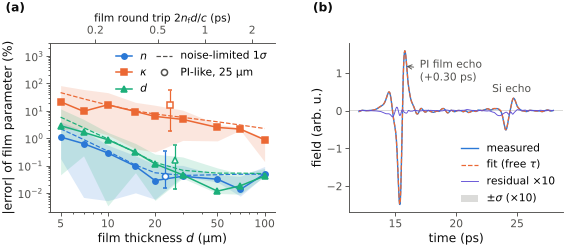

In [13]:
# per-thickness error arrays: 13 draws at 5-20 um (3 loop-0 + 10 loop-1, polished), 3 draws at 30-100 um
E = {q: [] for q in ('n', 'kappa', 'd')}
for i, d in enumerate(D_FILMS):
    rr = [r for r in rows_b if abs(r['d_film_um'] - d * 1e6) < 1e-6]
    new = errs(rr, pol=True) if rr else (np.array([]),) * 3
    for qi, q in enumerate(('n', 'kappa', 'd')):
        E[q].append(np.abs(np.r_[err[q][i], new[qi]]))
n_draws_fig = [len(e) for e in E['n']]
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=ps.figsize(1.0, height_cm=6.2), gridspec_kw=dict(width_ratios=[1.05, 1], wspace=0.34, left=0.1, right=0.99, top=0.8, bottom=0.17))
dum = D_FILMS * 1e6
for q, lab, c, mk in (('n', '$n$', ps.ROLE['n'], 'o'), ('kappa', r'$\kappa$', ps.ROLE['k'], 's'), ('d', '$d$', ps.ROLE['d'], '^')):
    e = [np.clip(v, 1e-5, None) for v in E[q]]
    ax1.fill_between(dum, [v.min() for v in e], [v.max() for v in e], color=c, alpha=0.16, lw=0)
    ax1.plot(dum, [np.median(v) for v in e], color=c, marker=mk, ms=3.5, lw=1.0, label=lab)
    ax1.plot(dum, [cc[f'{q}_percent'] for cc in cr_A], color=c, lw=0.8, ls='--')
    j25 = int(np.argmin(np.abs(D_PIL - 25e-6))); qq = c11c[j25]
    xo = 25 * {'n': 0.93, 'kappa': 1.0, 'd': 1.075}[q]
    med = qq['median_abs_err_percent'][q]; lo, hi = qq['range_abs_err_percent'][q]
    ax1.errorbar([xo], [med], yerr=[[med - max(lo, 1e-5)], [hi - med]], fmt=mk, ms=4, mfc='white', mec=c, mew=1.0, ecolor=c, elinewidth=0.8, capsize=1.5, zorder=6)
ax1.plot([], [], color=ps.INK2, lw=0.8, ls='--', label=r'noise-limited 1$\sigma$')
ax1.plot([], [], 'o', ms=4, mfc='white', mec=ps.INK2, mew=1.0, label='PI-like, 25 µm')
ax1.set_xscale('log'); ax1.set_yscale('log'); ax1.set_xlabel('film thickness $d$ (µm)'); ax1.set_ylabel('|error| of film parameter (%)')
ax1.set_xticks([5, 10, 20, 50, 100]); ax1.set_xticklabels(['5', '10', '20', '50', '100'])
ax1.legend(loc='upper right', ncol=2, columnspacing=0.8, handlelength=1.5, fontsize=7)
ax1.set_ylim(2e-3, 3e3)
axt = ax1.twiny(); axt.set_xscale('log'); axt.set_xlim(ax1.get_xlim())
tt = np.array([0.2, 0.5, 1, 2]); axt.set_xticks(tt / (2 * N_FILM / C0 * 1e12) * 1e6); axt.set_xticklabels([f'{v:g}' for v in tt])
axt.set_xlabel(r'film round trip $2 n_{\rm f} d / c$ (ps)', fontsize=7); axt.tick_params(labelsize=7)
axt.xaxis.set_minor_locator(plt.NullLocator())
axt.spines['top'].set_visible(True)
ps.despine(ax1)
w = (t_B > 12) & (t_B < 28)
ax2.axhspan(-10 * SIGMA_B, 10 * SIGMA_B, color=ps.NEUTRAL, alpha=0.35, lw=0, label=r'$\pm\sigma$ ($\times10$)')
ax2.plot(t_B[w], y_B[w], color=ps.ROLE['sample'], lw=0.9, label='measured')
ax2.plot(t_B[w], y_fit_v[w], color=ps.ROLE['fit'], lw=0.8, ls='--', label=r'fit (free $\tau$)')
ax2.plot(t_B[w], 10 * resid_v[w], color=ps.ROLE['residual'], lw=0.6, label=r'residual $\times10$')
ax2.set_xlabel('time (ps)'); ax2.set_ylabel('field (arb. u.)')
hh, ll = ax2.get_legend_handles_labels(); order = [1, 2, 3, 0]
ax2.legend([hh[i] for i in order], [ll[i] for i in order], loc='lower right', fontsize=7)
ie = ip + int(round(2 * p_hat[1] * p_hat[5] / C0 / dt_B)); ie = ie - 15 + int(np.argmax(y_B[ie - 15: ie + 15]))
ax2.annotate('Si echo', (t_B[ie], y_B[ie]), xytext=(0, 6), textcoords='offset points', fontsize=7, color=ps.INK2, ha='center', va='bottom')
t_film = 2 * bv['nd_PI_um'] * 1e-6 / C0 * 1e12                                   # film round trip of the Fig. 2(b) variant
jf = int(np.argmin(np.abs(t_B - (t_B[ip] + t_film))))
ax2.annotate(f'PI film echo\n(+{t_film:.2f} ps)', (t_B[jf], y_fit_v[jf]), xytext=(17.0, 1.05), textcoords='data', fontsize=7,
             color=ps.INK2, ha='left', va='center', arrowprops=dict(arrowstyle='->', color=ps.INK2, lw=0.6))
ps.despine(ax2)
ps.panel_label(ax1, 'a', x=-0.2, y=1.17); ps.panel_label(ax2, 'b', x=-0.17, y=1.17)
ps.savefig(fig, '../figs/fig2_thin_film')
plt.show()
LOOP1['fig2_data'] = dict(PI_film_round_trip_ps_marked=t_film, n_draws_per_thickness=dict(zip([f'{v:g}' for v in dum], n_draws_fig)),
                          median_abs_err_percent={q: [float(np.median(v)) for v in E[q]] for q in E},
                          range_abs_err_percent={q: [[float(v.min()), float(v.max())] for v in E[q]] for q in E},
                          sigma_PI=SIGMA_B, residual_scale=10)

In [14]:
LOOP1['timings_s'] = T_LOOP1
LOOP1['figure_export'] = ps.FONT_LOG
results['loop1_checks'] = LOOP1
json.dump(ps.to_jsonable(results), open('../results/nb2.json', 'w'), indent=1)
print('wrote ../results/nb2.json with loop1_checks:', list(LOOP1))

wrote ../results/nb2.json with loop1_checks: ['date', 'source', 'C14_noise_table', 'C1_PI_model_variants', 'C6_PI_cramer_rao_tau_amp', 'independent_nd_visible_index_times_profilometer_um', 'C11_sweep', 'fig2b_variant', 'fig2_data', 'timings_s', 'figure_export']
